In [1]:
import pandas as pd

df = pd.read_csv("housing_prices.csv")

print(df.head())
print(df.shape)
print(df.columns)

   id   price  bedrooms  bathrooms  sqft_living  sqft_lot  floors  waterfront  \
0   1  221900         3       1.00         1180      5650       1           0   
1   2  538000         3       2.25         2570      7242       2           0   
2   3  180000         2       1.00          770     10000       1           0   
3   4  604000         4       3.00         1960      5000       1           0   
4   5  510000         3       2.00         1680      8080       1           0   

   view  condition  ...  sqft_above  sqft_basement  yr_built  yr_renovated  \
0     0          3  ...        1180              0      1955             0   
1     0          3  ...        2170            400      1951          1991   
2     0          3  ...         770              0      1933             0   
3     0          5  ...        1050            910      1965             0   
4     0          3  ...        1680              0      1987             0   

   zipcode      lat     long  sqft_living15 

In [2]:
# Dataset information
print("Dataset Information:")
df.info()

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Statistical summary
print("\nStatistical Summary:")
print(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             50 non-null     int64  
 1   price          50 non-null     int64  
 2   bedrooms       50 non-null     int64  
 3   bathrooms      50 non-null     float64
 4   sqft_living    50 non-null     int64  
 5   sqft_lot       50 non-null     int64  
 6   floors         50 non-null     int64  
 7   waterfront     50 non-null     int64  
 8   view           50 non-null     int64  
 9   condition      50 non-null     int64  
 10  grade          50 non-null     int64  
 11  sqft_above     50 non-null     int64  
 12  sqft_basement  50 non-null     int64  
 13  yr_built       50 non-null     int64  
 14  yr_renovated   50 non-null     int64  
 15  zipcode        50 non-null     int64  
 16  lat            50 non-null     float64
 17  long           50 non-null     floa

Total missing values: 0


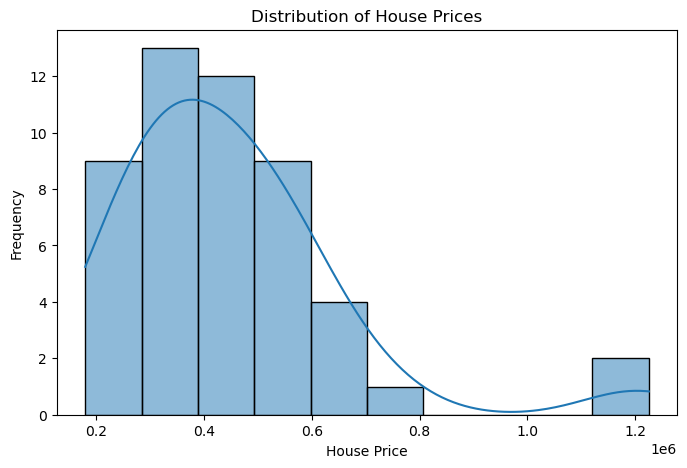

In [3]:
# Check missing values
print("Total missing values:", df.isnull().sum().sum())

# Import libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Price distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["price"], bins=10, kde=True)
plt.title("Distribution of House Prices")
plt.xlabel("House Price")
plt.ylabel("Frequency")
plt.show()

Correlation with Price:
price            1.000000
sqft_living      0.909573
grade            0.896771
bathrooms        0.851470
sqft_living15    0.817454
sqft_above       0.714449
bedrooms         0.692485
sqft_lot15       0.660600
sqft_lot         0.658874
sqft_basement    0.631273
condition        0.519344
view             0.506545
waterfront       0.506545
yr_built         0.416387
lat              0.388737
long             0.364709
floors           0.283763
yr_renovated     0.029774
id              -0.041893
zipcode         -0.240137
Name: price, dtype: float64


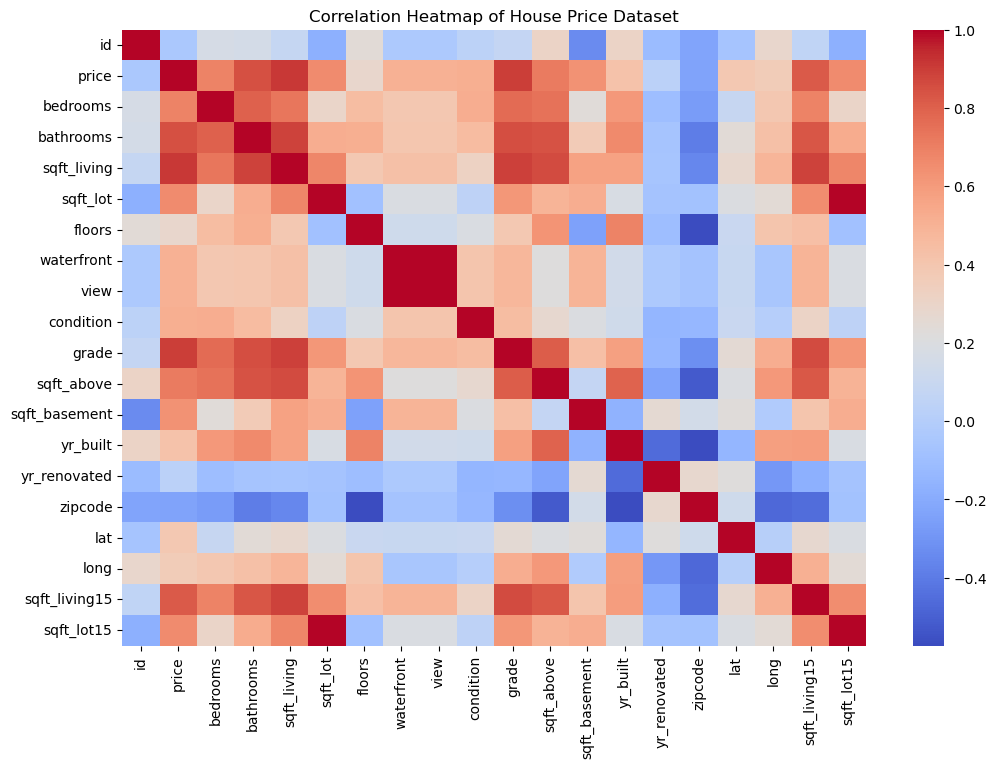

In [4]:
# Select numerical columns
numeric_df = df.select_dtypes(include=["number"])

# Correlation with price
print("Correlation with Price:")
print(numeric_df.corr()["price"].sort_values(ascending=False))

# Correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(numeric_df.corr(), cmap="coolwarm", annot=False)
plt.title("Correlation Heatmap of House Price Dataset")
plt.show()

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Select features and target
features = ["bedrooms", "bathrooms", "sqft_living", "sqft_lot", "grade"]
X = df[features]
y = df["price"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Evaluate model
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R-squared (R2 Score):", round(r2, 4))

Training rows: 40
Testing rows: 10
Mean Squared Error (MSE): 4976395285.0
Root Mean Squared Error (RMSE): 70543.57
R-squared (R2 Score): 0.6424


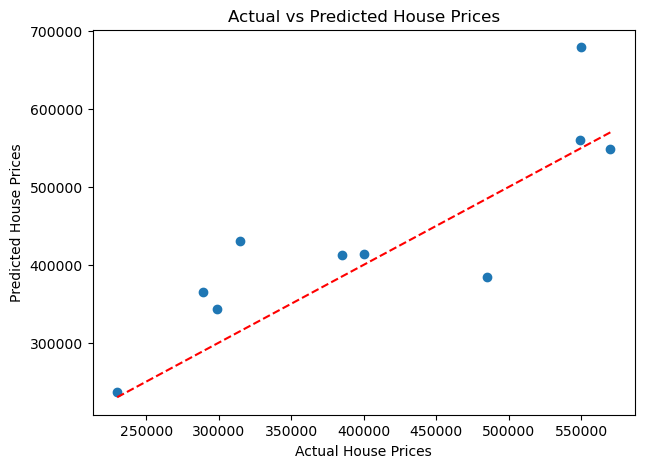

In [6]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")

# Ideal prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.show()

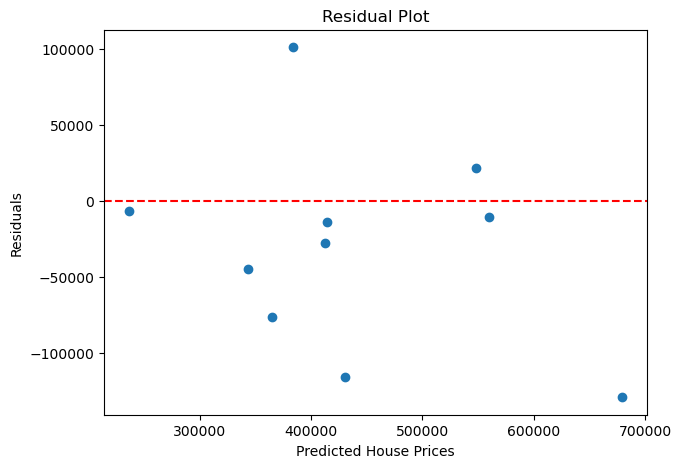

In [7]:
# Calculate residuals
residuals = y_test - y_pred

# Plot residuals
plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals)

plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Predicted House Prices")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

In [ ]:
# Display feature coefficients
coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": model.coef_
})

print(coefficients.sort_values(
    by="Coefficient",
    ascending=False
))

print("\nIntercept:", model.intercept_)